# 1 Introducción

El siguiente ejemplo que rota 90° una imagen cuadratica (700*700). El cálculo del filtro se aplicando la transpuesta de la matriz de la imagen. Por lo que para eso se aplica la siguiente formula a cada color RGB del pixel:

<center>$ pixel(y,x) = pixel(x,y)</center>

EL objetivo es enseñar el funcionamiento del Lenguaje Python, CUDA y el manejo de imagenes a bajo nivel. El ejemplo es ilustrativo, ya que internamente el módulo Pillow posee varios filtros integrados.

-----
#Enunciado del Ejercicio

a)  Teniendo en cuenta el código secuencial del Filtro de Rotar 90° una imagen, que se ejecuta en la CPU, genere el kernel para ejecutar el mismo algoritmo en forma paralela en la gpu

---
## 2 Armado del ambiente
Toma la direcciòn web de una imagen con  acceso público en internet, la deja disponible al contexto de ejecuciòn del cuaderno colab.

In [5]:
#@title # 2.1 Parámetros de ejecución
#@markdown ---
#@markdown ### Especifique la URL de la imagen:
url_imagen = "https://raw.githubusercontent.com/soa-pc-unlam/ProgramacionConcurrente/main/Enunciados%20TPs/TP-GPU/Imagenes/MK%20700x700.jpg" #@param {type:"string"}

#@markdown ---
# Leo la imagen desde internet.
#!wget https://github.com/wvaliente/SOA_HPC/blob/main/unlam.jpg?raw=true -O imagen.jpg

# TODO: Mejorar informaciòn y resutlado de ejecución.
!wget {url_imagen} -O imagen.jpg



--2026-11-26 02:15:12--  https://raw.githubusercontent.com/soa-pc-unlam/ProgramacionConcurrente/main/Enunciados%20TPs/TP-GPU/Imagenes/MK%20700x700.jpg
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 110405 (108K) [image/jpeg]
Saving to: ‘imagen.jpg’

imagen.jpg          100%[===================>] 107.82K  --.-KB/s    in 0.007s  

2026-11-26 02:15:12 (14.1 MB/s) - ‘imagen.jpg’ saved [110405/110405]



---
## 2.2 Instala en el cuaderno el módulo CUDA de Python.

In [6]:
!pip install pycuda

---
# 3 Desarrollo
# Ejecución en CPU
Ejecución del algoritmo del filtro de rotar 90° ejecutandose en forma secuencial en  la CPU

Imagen Original



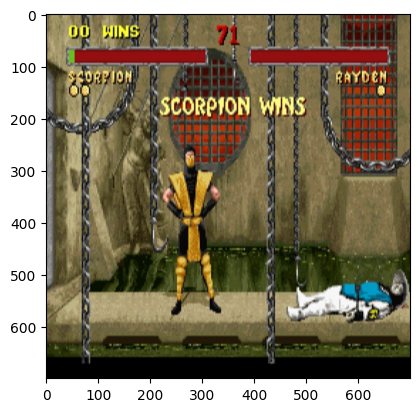

Imagen con Filtro



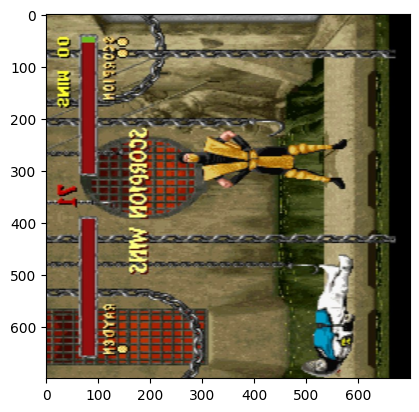

         10290055 function calls (10290054 primitive calls) in 7.903 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.565    0.282    7.180    7.180 2778906180.py:14(rotate_image)
   490000    0.917    0.000    3.697    0.000 Image.py:1645(getpixel)
   490000    1.122    0.000    3.641    0.000 Image.py:2061(putpixel)
   980001    1.501    0.000    3.174    0.000 Image.py:884(load)
   490000    0.384    0.000    2.080    0.000 ImageFile.py:273(load)
  1960001    1.188    0.000    1.716    0.000 Image.py:553(im)
  1470000    0.595    0.000    0.595    0.000 Image.py:580(readonly)
  1960002    0.529    0.000    0.529    0.000 {built-in method builtins.isinstance}
   980000    0.416    0.000    0.416    0.000 {method 'pixel_access' of 'ImagingCore' objects}
   490000    0.338    0.000    0.338    0.000 {method 'putpixel' of 'ImagingCore' objects}
   490000    0.243    0.000    0.243    0.000 {method 'getpixel' 

In [7]:
from pickle import FALSE
from PIL import Image
import matplotlib.pyplot as plt

import cProfile

# Poner SHOW_STATS en true para ver el tiempo de ejecucion y false para ocultarlo
SHOW_STATS = True

CM = 1/2.54
SIZE = 12*CM

# Funcion que aplica el filtro para rotar la imagen 90°
def rotate_image(width, height, im,out):
  for x in range(width):
      for y in range(height):
          pixel = im.getpixel((x,y))
          out.putpixel((y,x),pixel)
  return out

def main():
  # Objeto del Profiler de python
  cprofiler = cProfile.Profile()

  # Se carga la imagen
  im = Image.open("imagen.jpg")
  width, height = im.size
  out = Image.new(mode='RGB', size=(height,width))

  # Se activa el profiler
  cprofiler.enable()
  out = rotate_image(width, height, im, out)

  # Se desactiva el profiler
  cprofiler.disable()

  out.save('rotateimage.jpg')

  # Se muestra la imagen original
  print("Imagen Original\n")
  plt.figure(figsize=(SIZE,SIZE))
  imgplot = plt.imshow( im)
  plt.show()

  # Se muestra la imagen con filtro
  print("Imagen con Filtro\n")
  plt.figure(figsize=(SIZE, SIZE))
  img2plot = plt.imshow(out)
  plt.show()

  cprofiler.print_stats(sort='cumulative') if SHOW_STATS == True else None

main()

# Ejecución en GPU
Ejecución del algoritmo del filtro de rotar 90° ejecutandose en forma paralela en  la GPU

Imagen del filtro: imagen.jpg -RGB- [700, 700]
Thread: [ 16 , 19  ], Bloque : [ 44 , 37 ]
Total de Thread: [ 704 , 703  ]  =  494912


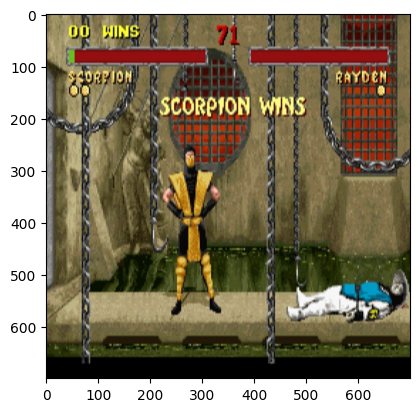

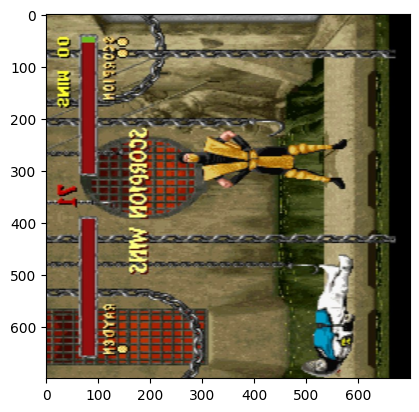

In [8]:
#%%writefile filter_brightness.py
%matplotlib inline
from datetime import datetime
tiempo_total = datetime.now()

import matplotlib.pyplot as plt
import numpy
from PIL import Image
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

# --------------------------------------------
# Definición de función que transforma el tiempo en  milisegundos
tiempo_en_ms = lambda dt:(dt.days * 24 * 60 * 60 + dt.seconds) * 1000 + dt.microseconds / 1000.0
# --------------------------------------------

CM = 1/2.54
SIZE = 12*CM
CANT_CHANNEL = 3

def define_kernel():
  module = SourceModule("""
  // Esta funcion es la de rotar la imagen de la misma forma que lo hace los programas anteriores sin usar el for, para los 3 canales(RGB)
  __global__ void kernel_img( int width, int height, int channels,int* img_O , int* img_R)
  {
      int idx = blockIdx.x * blockDim.x + threadIdx.x;
      int idy = blockIdx.y * blockDim.y + threadIdx.y;
      if (idx < width && idy < height)
      {
          int idx_O = (idy * width + idx) * channels;
          int idx_R = (idx * height + idy) * channels;
          for (int c = 0; c < channels; c++)
          {
              img_R[idx_R + c] = img_O[idx_O + c];
          }
      }
  }

  """)

  return module

def main():
  img_nombre = 'imagen.jpg'
  image = Image.open( img_nombre )

  # Summarize some details about the image
  img_ancho, img_alto  = image.size

  # Convierto la imagen comprimida en JPEG/PNG a array
  img_O_cpu = numpy.asarray(image)
  img_O_cpu = img_O_cpu.astype( numpy.int32() )
  img_R_cpu = numpy.empty_like( img_O_cpu)

  # Reservo los 2 vectores en GPU(3 pixeles usa RGB * (el tamaño del array))
  img_O_gpu = cuda.mem_alloc( img_O_cpu.nbytes )
  img_R_gpu = cuda.mem_alloc( img_R_cpu.nbytes )

  # GPU - Copio la memoria al GPU.
  cuda.memcpy_htod( img_O_gpu, img_O_cpu )
  cuda.memcpy_htod( img_R_gpu, img_R_cpu )

  # CPU - Defino la función kernel que ejecutará en GPU.
  module = define_kernel()

  # Muestro los atributos de la imagen y como se ve antes del seudo filtro.
  print("Imagen del filtro: " + img_nombre + " -" + image.mode + "- [" + str(img_ancho) + ", " + str(img_alto ) + "]" )

  # CPU - Genero la función kernel.
  kernel = module.get_function("kernel_img")

  dim_hilo_x = 16
  dim_bloque_x = int( (img_ancho+dim_hilo_x-1) / dim_hilo_x )

  dim_hilo_y = 19
  dim_bloque_y = int( (img_alto+dim_hilo_y-1) / dim_hilo_y )

  print( "Thread: [", dim_hilo_x, ",", dim_hilo_y, " ], Bloque : [", dim_bloque_x, ",", dim_bloque_y, "]" )
  print( "Total de Thread: [", dim_hilo_x*dim_bloque_x, ",", dim_hilo_y*dim_bloque_y, " ]", " = ", dim_hilo_x*dim_bloque_x*dim_hilo_y*dim_bloque_y )

  kernel( numpy.int32(img_ancho), numpy.int32(img_alto),numpy.int32(CANT_CHANNEL), img_O_gpu, img_R_gpu, block=( dim_hilo_x, dim_hilo_y, 1 ), grid=(dim_bloque_x, dim_bloque_y,1))

  # GPU - Copio el resultado desde la memoria GPU.
  cuda.memcpy_dtoh( img_R_cpu, img_R_gpu )

  # Muestro la imagen Original el filtro.
  plt.figure(figsize=(SIZE,SIZE))
  imgplot=plt.imshow( img_O_cpu )

  # Muestro la imagen luego de aplicarle el filtro.
  plt.figure(figsize=(SIZE, SIZE))
  imgplot=plt.imshow( img_R_cpu )

main()

In [9]:
!nsys profile --stats=true python filter_brightness.py

python3: can't open file '/content/filter_brightness.py': [Errno 2] No such file or directory
Generating '/tmp/nsys-report-4593.qdstrm'
[1/8] [========================100%] report1.nsys-rep
[2/8] [========================100%] report1.sqlite
[3/8] Executing 'nvtx_sum' stats report
SKIPPED: /content/report1.sqlite does not contain NV Tools Extension (NVTX) data.
[4/8] Executing 'osrt_sum' stats report

 Time (%)  Total Time (ns)  Num Calls  Avg (ns)  Med (ns)  Min (ns)  Max (ns)  StdDev (ns)         Name        
 --------  ---------------  ---------  --------  --------  --------  --------  -----------  -------------------
     33.2          754,681        268   2,816.0   2,109.0     1,006    26,571      2,374.2  stat64             
     30.5          693,770         60  11,562.8   3,647.0     1,440    90,419     18,822.6  read               
     20.1          458,190         60   7,636.5   7,040.0     4,226    48,665      5,518.9  open64             
      6.3          143,120         

---
# 4 Tabla de pasos


 Procesador | Funciòn | Detalle
------------|---------|----------
CPU      |  wget url_imagen       | Lectura de la direcciòn URL de la imagen (jpg) a procesar.
CPU      | pip install pycuda    | Instala en el cuaderno los driver de CUDA para Python.
CPU      |  matplotlib inline    | Macro de Colab para mostrar imagenes.
CPU      |  import                | Importa los módulos para funcionar.
CPU      |  datetime.now()        | Toma el tiempo actual.
CPU      |  Image.open()          | Abre el archivo de la imagen.
CPU      |  numpy.asarray(imagen) | Convierte el formato comprimido JPG a RAW.
CPU      |  numpy.empty_like(()   | Genera el array destino, que tendrá a la imagen resultado.
**GPU**  |  cuda.mem_alloc()      | Reserva la memoria para las imagenes en GPU.
**GPU**  |  cuda.memcpy_htod()    | Copio los valores en crudo de las imagenes al GPU.
CPU      |  SourceModule()        | Posee el còdigo del kernel.
CPU      |  module.get_function() | convierte el texto del kernel en funcion de Python.
CPU      |  dim_hilo_x, dim_hilo_y| Calcula las dimensiones para la ejecuciòn de 2D.
**GPU**  |  kernel()              | Ejecuta el kernel en GPU, enviando los parametros.
CPU      |  print()               | Informa los atributos de la imagen.
CPU      | cuda.memcpy_dtoh()     | Copia desde la memoria GPU al CPU.
CPU      |  plt.imshow            | Muestra la imagen original.
CPU      |  plt.imshow            | Muestra la imagen resultado.



---
# 5 Conclusiones

Las conclusiones son explicadas en clase...

---
# 6 Bibliografía

[1] MARKDOWN SYNTAX Colab: [PDF](https://github.com/wvaliente/SOA_HPC/blob/main/Documentos/markdown-cheatsheet-online.pdf)

[2] Introducción a Python: [Página Colab](https://github.com/wvaliente/SOA_HPC/blob/main/Documentos/Python_Basico.ipynb)

[3] Tutorial Point Colab: [PDF](https://github.com/wvaliente/SOA_HPC/blob/main/Documentos/markdown-cheatsheet-online.pdf)

[4] Algoritmo de filtro para rotar 90° una imagen en forma secuencial [PDF](https://www.youtube.com/watch?v=VFDWL0UuxN8)
